# Local calibration and streamed prediction

This offline example composes spatial-temporal out-of-fold beta calibration with AdaSTEM. It uses a small synthetic fixture with known marginal probabilities, two ensembles and two workers. It demonstrates the API and diagnostics; it does not establish a best calibration method or validate a copula estimator. Original examples remain unchanged.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import tempfile
import time
import numpy as np
import pandas as pd
from scipy.special import expit
from sklearn.ensemble import RandomForestClassifier
from IPython.display import Image, display
from stemflow.model.AdaSTEM import AdaSTEMClassifier
from stemflow.model_selection import ST_train_test_split
from stemflow.lazyloading import training_databases
from stemflow.calibration import (BetaCalibrator, CrossValidatedCalibratedClassifier,
    SpatioTemporalKFold, calibration_scores, plot_calibration_diagnostics)

In [2]:
rng = np.random.default_rng(42)
X = pd.DataFrame({"longitude": rng.uniform(-100, -70, 2500),
    "latitude": rng.uniform(25, 50, 2500), "DOY": rng.integers(121, 201, 2500),
    "environment": rng.normal(size=2500)})
truth = expit(-2.5 + X.environment + .8*np.sin((X.DOY-121)/80*np.pi))
y = pd.Series(rng.binomial(1, truth), index=X.index, name="occ")
X_train, X_test, y_train, y_test = ST_train_test_split(X, y.to_frame(),
    Spatio_blocks_count=10, Temporal_blocks_count=5, test_size=.25, random_state=42)
print(f"Training rows/events: {len(X_train)}/{int(y_train.occ.sum())}")
print(f"Held-out rows/events: {len(X_test)}/{int(y_test.occ.sum())}")

Training rows/events: 1896/309
Held-out rows/events: 604/103


Each stixel receives three retained fold models and one identity-regularized beta map. Longitude/latitude metadata are supplied automatically to the CV wrapper and excluded from forest predictors; DOY remains a predictor. The generic wrapper can also be fitted directly outside AdaSTEM. Set `sample_weights_for_classifier=False` for this unweighted strategy.

Measured fit: 2.762s; streamed prediction: 1.577s
{'aggregation_backend': 'streaming', 'accumulator_bytes': 12080, 'rows': 604, 'ensembles': 2}
Matrix and streaming outputs agree; temporary databases/maps/models removed.


/Users/chenyangkang/Desktop/optimize_adastem/stemflow/stemflow/utils/validation.py:414: UserWarning: The grid_len_upper_threshold is larger than the scale of longitude and latitude (x and y). Be sure if this is desired.
  warnings.warn(
/Users/chenyangkang/Desktop/optimize_adastem/stemflow/stemflow/utils/validation.py:160: UserWarning: Input X is pandas dataframe; self.max_mem is not used.
  warnings.warn('Input X is pandas dataframe; self.max_mem is not used.')
/Users/chenyangkang/Desktop/optimize_adastem/stemflow/stemflow/model/AdaSTEM.py:1025: UserWarning: There are 11.6% points (70 points) falling out of predictable range.
  warnings.warn(f"There are {100 * missing / len(mean):.3g}% points ({missing} points) falling out of predictable range.")
/Users/chenyangkang/Desktop/optimize_adastem/stemflow/stemflow/utils/validation.py:160: UserWarning: Input X is pandas dataframe; self.max_mem is not used.
  warnings.warn('Input X is pandas dataframe; self.max_mem is not used.')
/Users/cheny

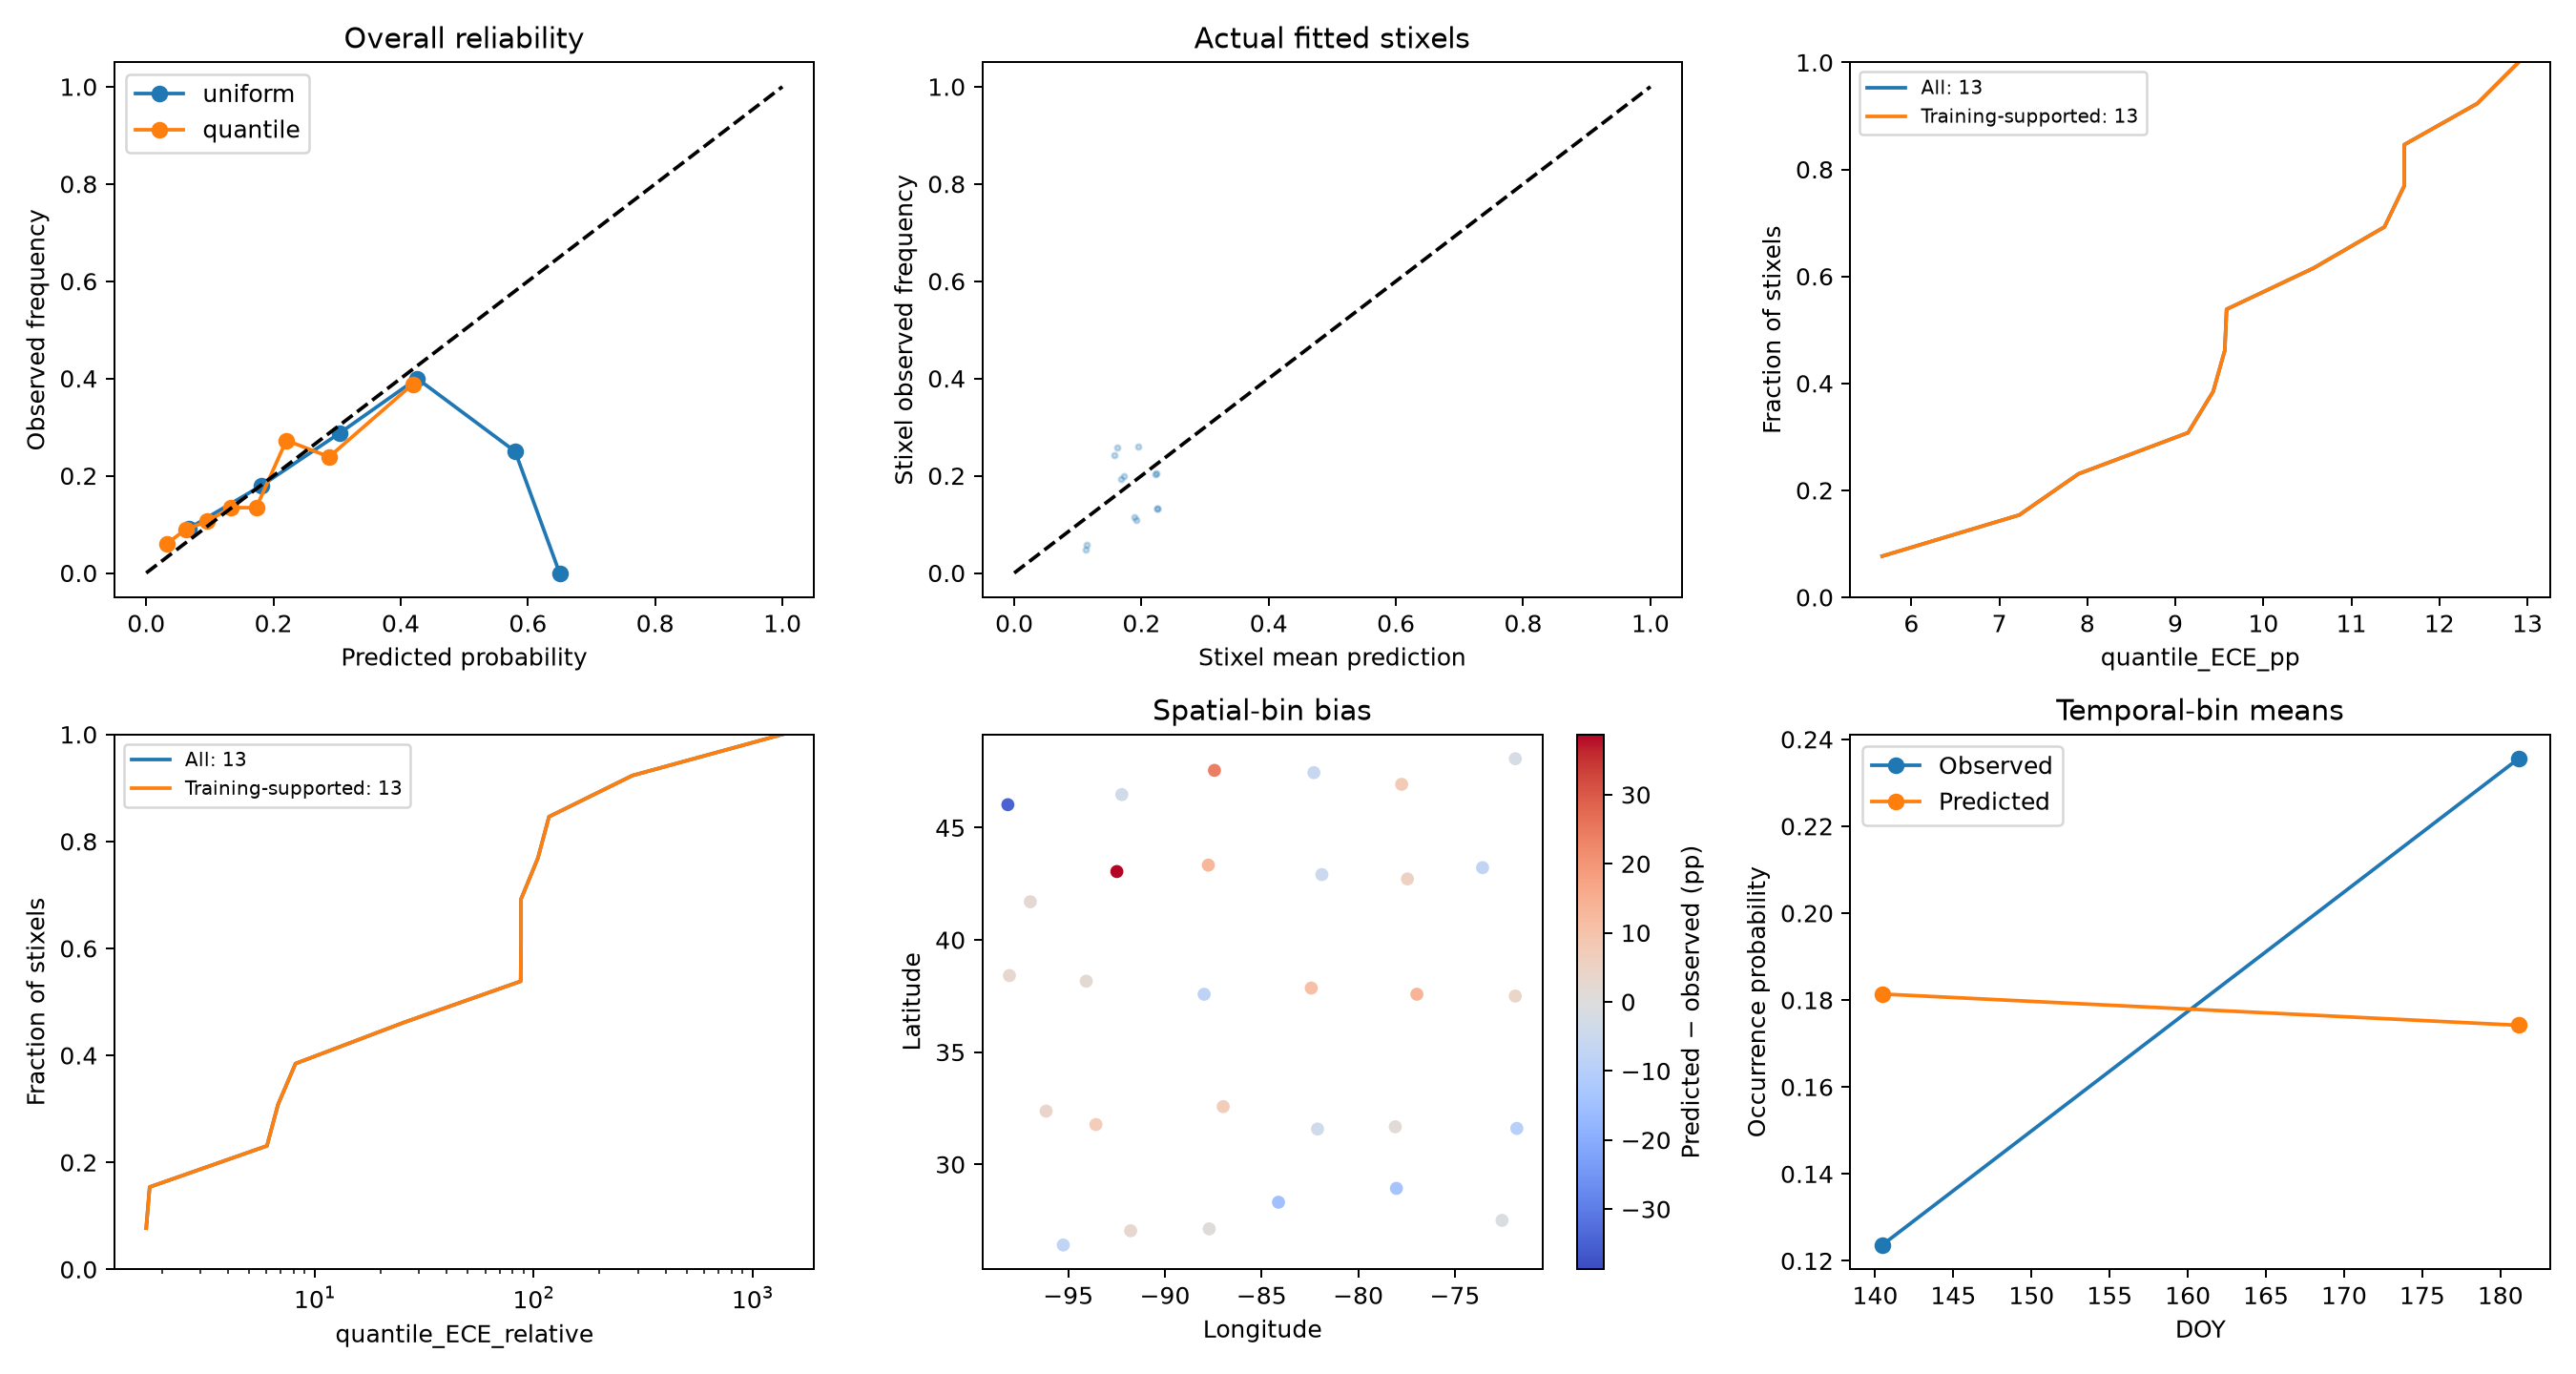

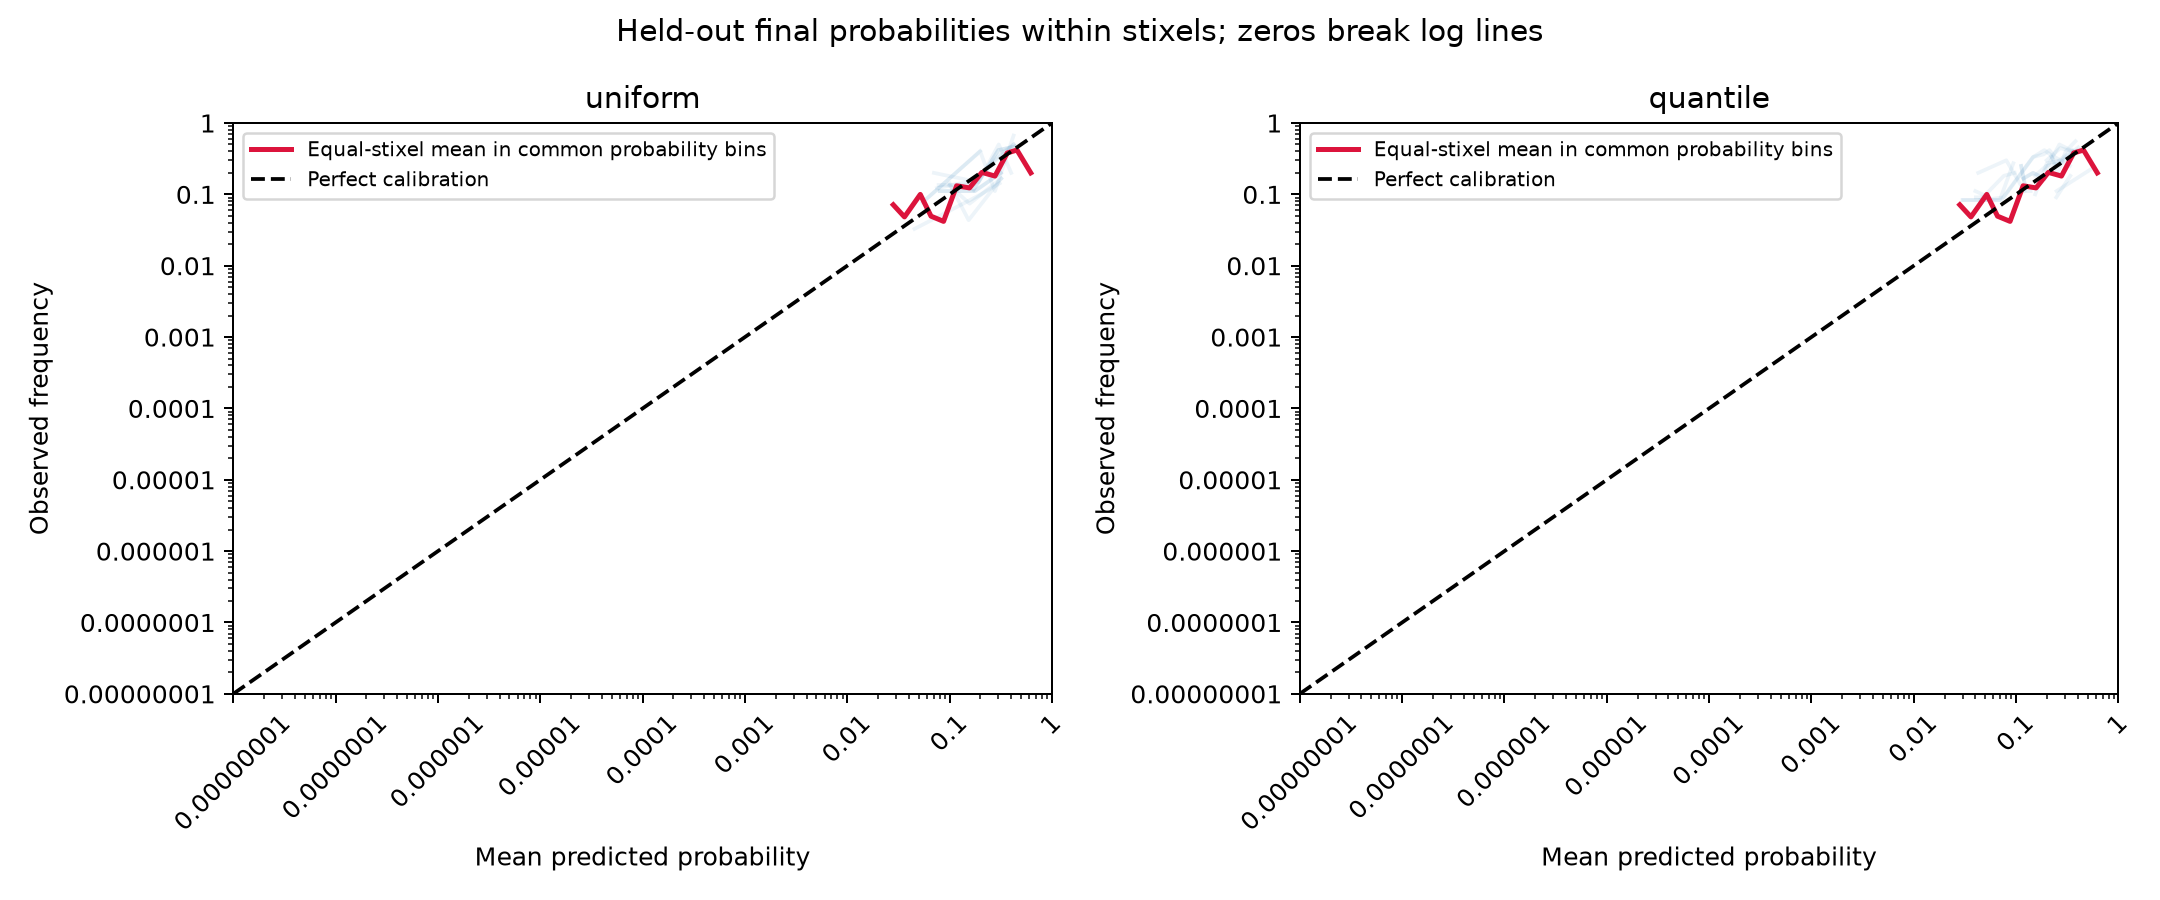

In [3]:
base = CrossValidatedCalibratedClassifier(
    RandomForestClassifier(n_estimators=15, max_depth=5, min_samples_leaf=10,
        n_jobs=1, random_state=42),
    BetaCalibrator(ridge=100), SpatioTemporalKFold(
        n_splits=3, Spatio_blocks_count=5, Temporal_blocks_count=5))
with tempfile.TemporaryDirectory(prefix="stemflow_example_") as scratch:
    model = AdaSTEMClassifier(base_model=base, ensemble_fold=2,
        min_ensemble_required=1, points_lower_threshold=200,
        grid_len_upper_threshold=25, grid_len_lower_threshold=5,
        temporal_start=121, temporal_end=201, temporal_step=40,
        temporal_bin_interval=40, temporal_bin_start_jitter=0,
        sample_weights_for_classifier=False, ensemble_bootstrap=True,
        lazy_loading=True, lazy_loading_dir=str(Path(scratch)/"models"),
        n_jobs=2, random_state=42, save_gridding_plot=False, verbosity=0)
    started = time.perf_counter()
    with training_databases(X_train, y_train, directory=scratch) as (xp, yp):
        model.fit(xp, yp, temporal_window_prequery=True,
            training_data_backend="memmap", inner_max_num_threads=1, persist_prediction_state=False)
    fit_seconds = time.perf_counter()-started
    started = time.perf_counter()
    probability, std = model.predict_proba(X_test, return_std=True,
        temporal_window_prequery=True)
    prediction_seconds = time.perf_counter()-started
    execution = model.prediction_execution_info_.copy()
    matrix, matrix_std = model.predict_proba(X_test, return_std=True,
        temporal_window_prequery=True, streaming=False)
    np.testing.assert_allclose(probability, matrix, atol=1e-12, equal_nan=True)
    np.testing.assert_allclose(std, matrix_std, atol=1e-12, equal_nan=True)
    diagnostics = model.calibration_diagnostics(X_test, y_test, probability[:, 1])
    plots = Path(scratch)/"plots"
    plot_calibration_diagnostics(diagnostics, plots, max_curves=100)
    display(Image(filename=str(plots/"calibration_diagnostics.png")))
    display(Image(filename=str(plots/"stixel_calibration_overlay.png")))
    del model
print(f"Measured fit: {fit_seconds:.3f}s; streamed prediction: {prediction_seconds:.3f}s")
print(execution)
print("Matrix and streaming outputs agree; temporary databases/maps/models removed.")

In [4]:
overall = diagnostics["scores"].query("level == 'overall'")
display(overall[["n_valid", "detections", "coverage", "AUC", "Brier", "log_loss",
    "quantile_ECE_pp", "quantile_ECE_relative", "quantile_zero_event_mass"]])
display(diagnostics["summary"].query("level == 'stixel' and scope == 'all'"))
valid = np.isfinite(probability[:, 1])
print("Mean absolute probability error against synthetic truth:",
    np.mean(np.abs(probability[valid, 1]-truth.loc[X_test.index].to_numpy()[valid])))

Mean absolute probability error against synthetic truth: 0.05857302724729497


,n_valid,detections,coverage,AUC,Brier,log_loss,quantile_ECE_pp,quantile_ECE_relative,quantile_zero_event_mass
0,534,95,0.884106,0.68861,0.138149,0.440132,2.962933,1.257356,0.0


,scope,level,metric,n_groups,q25,median,q75,p90
39,all,stixel,ECE_pp,13,6.289101,10.347896,12.073925,12.673491
40,all,stixel,quantile_ECE_pp,13,9.144071,9.581934,11.600573,12.264075
41,all,stixel,ECE_relative,13,1.833810,3.581784,5.260476,13.065703
42,all,stixel,quantile_ECE_relative,13,6.786653,87.165377,104.582707,249.160122
43,all,stixel,quantile_relative_floor_1e8,13,12.316270,450.157058,614.738834,2329.851895
44,all,stixel,quantile_zero_event_mass,13,0.129412,0.355556,0.375000,0.472325
45,all,stixel,bias_pp,13,-2.754725,1.996127,7.452973,8.947764
46,all,stixel,rate_ratio,13,0.862264,1.098559,1.683144,1.934152
47,all,stixel,AUC,13,0.581197,0.673077,0.687805,0.784070
48,all,stixel,average_precision,13,0.160989,0.361781,0.437178,0.500003


The red overlay averages actual common probability intervals, including observed zeros before plotting. Zero observations break logarithmic lines. Training-supported stixels use training counts, not held-out labels. Sparse bins and overlapping stixels limit interpretation of relative ECE; support counts, expected detections, loss and coverage should accompany it. The regression wrapper calibrates point means only. Detailed profiling is opt-in through `STEMFLOW_PROFILE_DIR`, `STEMFLOW_PROFILE_LINES` and `STEMFLOW_PROFILE_ALLOCATIONS`; run those profiles separately from timing comparisons. See [local calibration and tuning](../Tips/Local_calibration_and_tuning.md) and [parallel execution](../Tips/Tips_for_parallel_execution.md).